In [1]:
from req_functions_from_ApproxSP import *
import pandas as pd
import json
from tqdm import tqdm
import time
from euclidean import *
from mallows import *
from AccompliceManipulation import *

In [2]:
## One for All

def no_regret(m, mpref, wpref, DA_match):
    original_m_pref = mpref[m - 1] 
    original_match = DA_match[m - 1]
    mpref_prime = copy.deepcopy(mpref)
    wNR = []

    for woman in original_m_pref:
        if woman != original_match:
            new_m_pref = []
            mpref_prime[m-1] = [woman] + [w for w in original_m_pref if w != original_match] 
            new_matching = gale_shapley(mpref_prime, wpref)
            if original_m_pref.index(new_matching[m-1]) < original_m_pref.index(original_match):
                wNR.append(woman)
    new_m_pref = wNR + [w for w in original_m_pref if w not in wNR]             
    return wNR, new_m_pref        
            


def one_for_all(mpref, wpref, accomplice):
    da_match = gale_shapley(mpref, wpref)
    
    no_regret_set_accomplice, new_m_pref = no_regret(accomplice, mpref, wpref, da_match)
    mpref_prime = copy.deepcopy(mpref)
    mpref_prime[accomplice - 1] = new_m_pref
    new_matching = gale_shapley(mpref_prime, wpref)
    return new_matching #used to have new_m_pref

In [3]:
def one_for_all_2(mpref, wpref, accomplice, da_match):
    original_match = da_match[accomplice - 1]
    original_m_pref = mpref[accomplice - 1]
    wNR = []
    mpref_prime = mpref.copy()

    for woman in original_m_pref:
        if woman != original_match:
            mpref_prime[accomplice-1] = [woman] + [w for w in original_m_pref if w != original_match] 
            new_matching = gale_shapley(mpref_prime, wpref)
            if original_m_pref.index(new_matching[accomplice-1]) < original_m_pref.index(original_match):
                wNR.append(woman)
    new_m_pref = wNR + [w for w in original_m_pref if w not in wNR]
    mpref_prime[accomplice - 1] = new_m_pref
    final = gale_shapley(mpref_prime, wpref)
    return final

In [14]:
import shutil

original_file = 'euclidean_mallows_accomplice.csv'
new_file = 'backup_euclidean_mallows.csv'

shutil.copy(original_file, new_file)

'backup_euclidean_mallows.csv'

**Mallows MA**

In [4]:
df = pd.read_csv('mallows_MA_accomplice.csv')

count_men = []

for i, row in tqdm(df.iterrows()):
    

    mpref = json.loads(row['mpref'])
    wpref = json.loads(row['wpref'])
    matching = gale_shapley(mpref, wpref)
    n = len(mpref)
    count = 0
    
    for accomplice in range (1, n+1):
        for manipulator in range(1, n+1):
            result = accomplice_manipulation(mpref, wpref, manipulator, accomplice)
            if result [0]!= matching:
                count += 1
                break

    count_men.append(count)

df['count_men'] = count_men

df.to_csv('mallows_MA_accomplice.csv', index=False)           

18000it [31:17,  9.59it/s]


**Euclidean Mallows**

In [15]:
df = pd.read_csv('euclidean_mallows_accomplice.csv')

count_men = []

for i, row in tqdm(df.iterrows()):
    

    mpref = json.loads(row['mpref'])
    wpref = json.loads(row['wpref'])
    matching = gale_shapley(mpref, wpref)
    n = len(mpref)
    count = 0
    
    for accomplice in range (1, n+1):
        for manipulator in range(1, n+1):
            result = accomplice_manipulation(mpref, wpref, manipulator, accomplice)
            if result [0]!= matching:
                count += 1
                break

    count_men.append(count)

df['count_men'] = count_men

df.to_csv('euclidean_mallows_accomplice.csv', index=False)           

18000it [1:55:50,  2.59it/s]


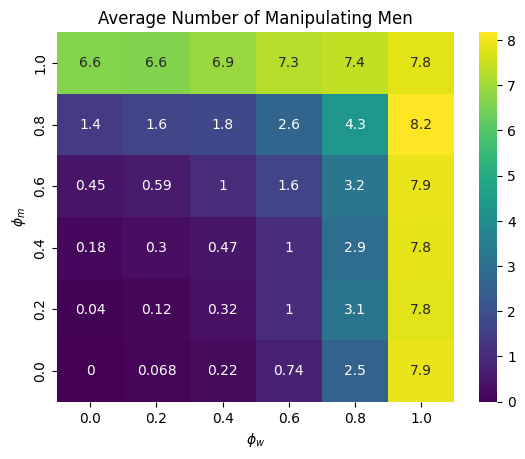

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

summary = df.groupby(['phi_m', 'phi_w']).agg({'count_men': 'mean'}).reset_index()

pivot_table = summary.pivot(index = 'phi_m', columns = 'phi_w', values = 'count_men')
sns.heatmap(pivot_table, annot=True, cmap="viridis")
plt.gca().invert_yaxis() 
plt.title("Average Number of Manipulating Men")
plt.xlabel("$\phi_w$")
plt.ylabel("$\phi_m$")
plt.savefig("one_for_all_euclidean_mallows.pdf", format='pdf')
plt.show()

**Mallows MD**

In [17]:
df = pd.read_csv('mallows_MD_accomplice.csv')

count_men = []

for i, row in tqdm(df.iterrows()):
    

    mpref = json.loads(row['mpref'])
    wpref = json.loads(row['wpref'])
    matching = gale_shapley(mpref, wpref)
    n = len(mpref)
    count = 0
    
    for accomplice in range (1, n+1):
        for manipulator in range(1, n+1):
            result = accomplice_manipulation(mpref, wpref, manipulator, accomplice)
            if result [0]!= matching:
                count += 1
                break

    count_men.append(count)

df['count_men'] = count_men

df.to_csv('mallows_MD_accomplice.csv', index=False)           

18000it [5:09:19,  1.03s/it] 


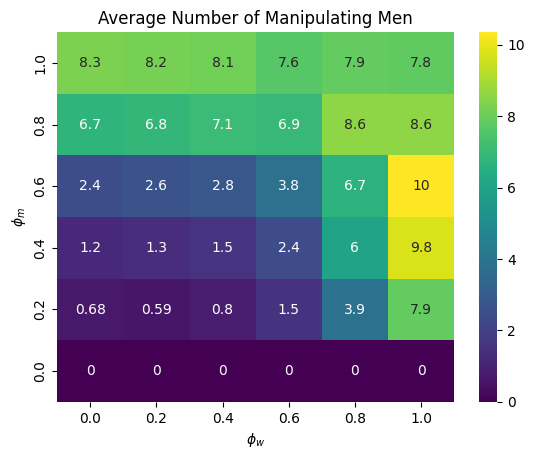

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

summary = df.groupby(['phi_m', 'phi_w']).agg({'count_men': 'mean'}).reset_index()

pivot_table = summary.pivot(index = 'phi_m', columns = 'phi_w', values = 'count_men')
sns.heatmap(pivot_table, annot=True, cmap="viridis")
plt.gca().invert_yaxis() 
plt.title("Average Number of Manipulating Men")
plt.xlabel("$\phi_w$")
plt.ylabel("$\phi_m$")
plt.savefig("one_for_all_mallows_MD.pdf", format='pdf')
plt.show()

**Mallows**

In [19]:
df = pd.read_csv('mallows_accomplice.csv')

count_men = []

for i, row in tqdm(df.iterrows()):
    

    mpref = json.loads(row['mpref'])
    wpref = json.loads(row['wpref'])
    matching = gale_shapley(mpref, wpref)
    n = len(mpref)
    count = 0
    
    for accomplice in range (1, n+1):
        for manipulator in range(1, n+1):
            result = accomplice_manipulation(mpref, wpref, manipulator, accomplice)
            if result [0]!= matching:
                count += 1
                break

    count_men.append(count)

df['count_men'] = count_men

df.to_csv('mallows_accomplice.csv', index=False)           

18000it [19:48:45,  3.96s/it] 


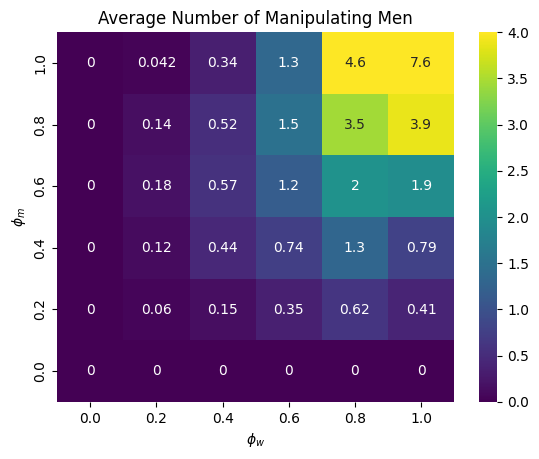

In [32]:
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('mallows_accomplice.csv')

summary = df.groupby(['phi_m', 'phi_w']).agg({'count_men': 'mean'}).reset_index()

pivot_table = summary.pivot(index = 'phi_m', columns = 'phi_w', values = 'count_men')
sns.heatmap(pivot_table, annot=True, cmap="viridis", vmax=4)
plt.gca().invert_yaxis() 
plt.title("Average Number of Manipulating Men")
plt.xlabel("$\phi_w$")
plt.ylabel("$\phi_m$")
plt.savefig("one_for_all_mallows.pdf", format='pdf')
plt.show()

**Reverse Euclidean**

In [21]:
df = pd.read_csv('reverse_euclidean_accomplice.csv')

count_men = []

for i, row in tqdm(df.iterrows()):
    

    mpref = json.loads(row['mpref'])
    wpref = json.loads(row['wpref'])
    matching = gale_shapley(mpref, wpref)
    n = len(mpref)
    count = 0
    
    for accomplice in range (1, n+1):
        for manipulator in range(1, n+1):
            result = accomplice_manipulation(mpref, wpref, manipulator, accomplice)
            if result [0]!= matching:
                count += 1
                break

    count_men.append(count)

df['count_men'] = count_men

df.to_csv('reverse_euclidean_accomplice.csv', index=False)           

15000it [7:15:01,  1.74s/it] 


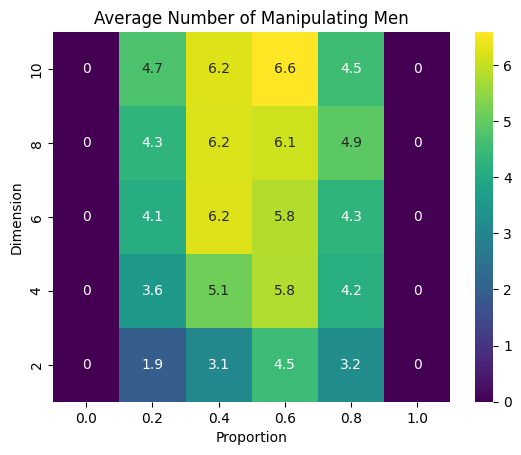

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

summary = df.groupby(['dimension', 'proportion']).agg({'count_men': 'mean'}).reset_index()

pivot_table = summary.pivot(index = 'dimension', columns = 'proportion', values = 'count_men')
sns.heatmap(pivot_table, annot=True, cmap="viridis")
plt.gca().invert_yaxis() 
plt.title("Average Number of Manipulating Men")
plt.xlabel("Proportion")
plt.ylabel("Dimension")
plt.savefig("one_for_all_reverse_euclidean.pdf", format='pdf')
plt.show()

**Expectations Euclidean**

In [23]:
df = pd.read_csv('expectations_euclidean_accomplice.csv')

count_men = []

for i, row in tqdm(df.iterrows()):
    

    mpref = json.loads(row['mpref'])
    wpref = json.loads(row['wpref'])
    matching = gale_shapley(mpref, wpref)
    n = len(mpref)
    count = 0
    
    for accomplice in range (1, n+1):
        for manipulator in range(1, n+1):
            result = accomplice_manipulation(mpref, wpref, manipulator, accomplice)
            if result [0]!= matching:
                count += 1
                break

    count_men.append(count)

df['count_men'] = count_men

df.to_csv('expectations_euclidean_accomplice.csv', index=False)           

15000it [28:25:04,  6.82s/it] 


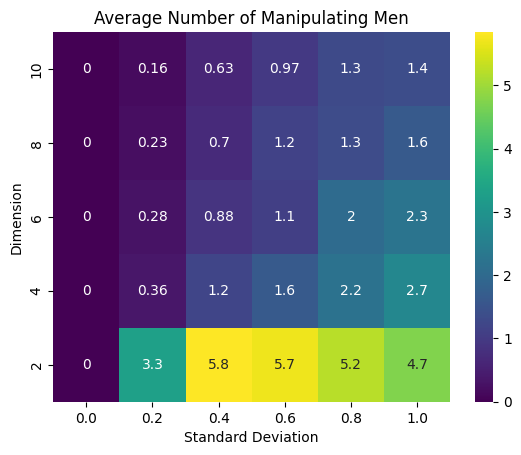

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

summary = df.groupby(['dimension', 'std']).agg({'count_men': 'mean'}).reset_index()

pivot_table = summary.pivot(index = 'dimension', columns = 'std', values = 'count_men')
sns.heatmap(pivot_table, annot=True, cmap="viridis")
plt.gca().invert_yaxis() 
plt.title("Average Number of Manipulating Men")
plt.xlabel("Standard Deviation")
plt.ylabel("Dimension")
plt.savefig("one_for_all_expectations_euclidean.pdf", format='pdf')
plt.show()

**Fame Euclidean**

In [25]:
df = pd.read_csv('fame_euclidean_accomplice.csv')

count_men = []

for i, row in tqdm(df.iterrows()):
    

    mpref = json.loads(row['mpref'])
    wpref = json.loads(row['wpref'])
    matching = gale_shapley(mpref, wpref)
    n = len(mpref)
    count = 0
    
    for accomplice in range (1, n+1):
        for manipulator in range(1, n+1):
            result = accomplice_manipulation(mpref, wpref, manipulator, accomplice)
            if result [0]!= matching:
                count += 1
                break

    count_men.append(count)

df['count_men'] = count_men

df.to_csv('fame_euclidean_accomplice.csv', index=False)           

12000it [3:44:14,  1.12s/it] 


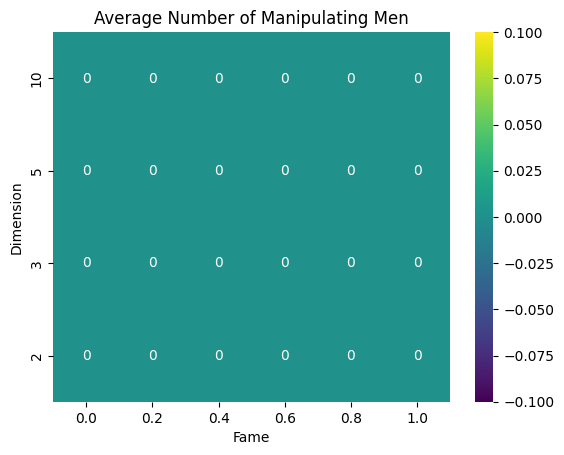

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt

summary = df.groupby(['dimension', 'fame']).agg({'count_men': 'mean'}).reset_index()

pivot_table = summary.pivot(index = 'dimension', columns = 'fame', values = 'count_men')
sns.heatmap(pivot_table, annot=True, cmap="viridis")
plt.gca().invert_yaxis() 
plt.title("Average Number of Manipulating Men")
plt.xlabel("Fame")
plt.ylabel("Dimension")
plt.savefig("one_for_all_fame_euclidean.pdf", format='pdf')
plt.show()